# 4_1_DengueTuning_ForecastGap
In this notebook, we work on tuning the dengue model in a "forecast the gap" setting. This means setting the output_chunk_shift to 0, and forecasting across the the data-forecast gap (15 weeks). A key difference here is that we will have to implement early stopping and validation loss computations manually as by default this is done in a rolling manner within Torch. Through this manual implementation, we can more accurately compute validation loss in seasonal forecasting scenarios.

In [1]:
import pandas as pd
import numpy as np
import torch 
import os
import json

from darts import TimeSeries, concatenate
from darts.utils.callbacks import TFMProgressBar
from darts.metrics import mape, smape, mse, rmse, mae, mql, ql
from darts.dataprocessing.transformers import Scaler
from darts.dataprocessing.transformers import StaticCovariatesTransformer
from sklearn.preprocessing import MinMaxScaler
import optuna
from optuna.samplers import TPESampler
from darts.models import (
    RandomForestModel,
    LinearRegressionModel,
    XGBModel,
    TFTModel,
    TiDEModel
)
from darts.utils.likelihood_models import GaussianLikelihood, PoissonLikelihood, QuantileRegression
import matplotlib.pyplot as plt
from pytorch_lightning.callbacks import Callback, EarlyStopping
import pickle
import helpers as hp

torch.set_float32_matmul_precision("medium")
pd.options.mode.copy_on_write = True
global_fit = False
include_stringency_index = False
random_seed = 20
accel = "gpu"

quantiles = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

# 1. Reading in Data

In [2]:
tuning_name = "TestNotebook"
base_dir = os.getcwd()
model_input_dir = os.path.join(base_dir, "ModelInput")
tuning_dir = os.path.join(base_dir, "Dengue Tuning", tuning_name)
climate_tuning_dir = os.path.join(base_dir, "Climate Tuning", "Notebook_24_07_2025")
climate_model_name = "RandomForest"
climate_forecast_dir = os.path.join(climate_tuning_dir, climate_model_name, "Forecasts")

os.makedirs(tuning_dir, exist_ok = True)

weekly_cal = pd.read_csv(os.path.join(model_input_dir, "Calendar.csv"))
weekly_cal = weekly_cal.iloc[1:]
climate_df = pd.read_csv(os.path.join(model_input_dir, "TimeVaryingCovs.csv"))
dengue_df = pd.read_csv(os.path.join(model_input_dir, "DengueCases.csv"))

#Remove uf = "ES" since there is no dengue data for Espirito Santo
climate_df = climate_df[climate_df["uf"] != "ES"]
dengue_df = dengue_df[dengue_df["uf"] != "ES"]

dengue_df = dengue_df[["epiweek", "Year", "Week", "uf", "uf_name", "Cases"]]

In [3]:
#Read the climate forecasts
clim_forecast_dict = hp.load_pickle(os.path.join(climate_forecast_dir, "forecast_dict.pkl"))
clim_forecast_log_dict = hp.load_pickle(os.path.join(climate_forecast_dir, "forecast_dict_log.pkl"))

In [4]:
clim_tuning_config = hp.read_json(os.path.join(climate_tuning_dir,"tuning_details.json"))
clim_var_names = clim_tuning_config["clim_var_names"]

#If boolean says we should include stringency index, then we add it into the climate variable names
if include_stringency_index:
    clim_var_names.append("StringencyIndex")

In [5]:
set_info = weekly_cal[["epiweek", "Year", "Week", "WeekStart", "WeekMid", "WeekEnd"]]


#Set up all the set information for splitting the dengue and climate data

#For tuning training 1a,b,c - val1a,b,c
set_info["den_train1a"] = set_info["epiweek"] <= 201825
set_info["den_train1b"] = set_info["epiweek"] <= 201925
set_info["den_train1c"] = set_info["epiweek"] <= 202025

set_info["den_val1a"] = (set_info["epiweek"] >= 201841) & (set_info["epiweek"] <= 201940)
set_info["den_val1b"] = (set_info["epiweek"] >= 201941) & (set_info["epiweek"] <= 202040)
set_info["den_val1c"] = (set_info["epiweek"] >= 202041) & (set_info["epiweek"] <= 202140)

set_info["den_ex"] = (set_info["epiweek"] >= 202141) & (set_info["epiweek"] <= 202225)

#Train - Val - Test for model evaluation
set_info["den_train1"] = set_info["epiweek"] <= 202110
set_info["den_train2"] = set_info["epiweek"] <= 202210
set_info["den_train3"] = set_info["epiweek"] <= 202310

set_info["den_val1"] = (set_info["epiweek"] >= 202126) & (set_info["epiweek"] <= 202225)
set_info["den_val2"] = (set_info["epiweek"] >= 202226) & (set_info["epiweek"] <= 202325)
set_info["den_val3"] = (set_info["epiweek"] >= 202326) & (set_info["epiweek"] <= 202425)

set_info["den_targ1"] = (set_info["epiweek"] >= 202241) & (set_info["epiweek"] <= 202340)
set_info["den_targ2"] = (set_info["epiweek"] >= 202341) & (set_info["epiweek"] <= 202440)
set_info["den_targ3"] = (set_info["epiweek"] >= 202441) & (set_info["epiweek"] <= 202540)

# set_info["clim_test"] = (set_info["epiweek"] >= 201841) & (set_info["epiweek"] <= 201940)
# set_info["clim_test_input"] = set_info["epiweek"] <= 201825


In [6]:
uf_list = climate_df["uf"].unique()
uf_mapper = climate_df[["uf", "uf_name"]].copy().drop_duplicates()
uf_dict = dict(zip(uf_mapper["uf"], uf_mapper["uf_name"]))
uf_name_list = [uf_dict[curr_uf] for curr_uf in uf_list]

# 2. Data Preparation

In [7]:
#Log transformed climate (just the precipitation columns)
log_trans_cols = ["precip_min", "precip_med", "precip_max"]
proc_climate_df = hp.transform_df_cols(climate_df, log_trans_cols, np.log1p)

#Log transformed dengue cases
proc_dengue_df = hp.transform_df_cols(dengue_df, ["Cases"], np.log1p)

In [8]:
#Create all the TimeSeries objects we need for tuning first
group_col = "uf"

#Dengue case TimeSeries
train1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1a")
train1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1b")
train1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1c")

val1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1a")
val1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1b")
val1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1c")

#Log transformed version of the cases TimeSeries for actual training
train1a_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1a")
train1b_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1b")
train1c_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1c")

#Climate values to use as covariates 
clim_train1a_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_train1a")
clim_train1b_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_train1b")
clim_train1c_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_train1c")

#These are just for checking, and won't be used in the actual forecasting since we use forecasted variables in the validation set
clim_val1a_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_val1a")
clim_val1b_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_val1b")
clim_val1c_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_val1c")

#Get the forecasts over the validation set to be used as future covariates
clim_preds_1a_log = clim_forecast_log_dict["clim_preds_1a"]
clim_preds_1b_log = clim_forecast_log_dict["clim_preds_1b"]
clim_preds_1c_log = clim_forecast_log_dict["clim_preds_1c"]


#Processing with COVID-19 stringency index (optional)
def intersect_stack(curr_shorter, curr_longer): 
    to_stack = curr_longer.slice_intersect(curr_shorter)
    return curr_shorter.stack(to_stack)

if include_stringency_index:
    #If including the StringencyIndex, then should at it to the climate forecasts
    #Since there is no StringencyIndex forecasting model, we assume it is 0 in forecasts
    temp_cal = weekly_cal.copy()
    temp_cal["WeekStart"] = pd.to_datetime(temp_cal["WeekStart"], format = "%Y-%m-%d")
    temp_cal = temp_cal.set_index("WeekStart")
    zero_series = TimeSeries.from_times_and_values(
        times = temp_cal.index,
        values = np.zeros(len(temp_cal)),
        columns=["StringencyIndex"]
    )
    
    #Add the zero series into the TimeSeries with predicted climate
    clim_preds_1a_log = [intersect_stack(curr_series, zero_series) for curr_series in clim_preds_1a_log]
    clim_preds_1b_log = [intersect_stack(curr_series, zero_series) for curr_series in clim_preds_1b_log]
    clim_preds_1c_log = [intersect_stack(curr_series, zero_series) for curr_series in clim_preds_1c_log]

## 2.1 Add Static Covariates

In [9]:
stat_covs = pd.read_csv(os.path.join(model_input_dir, "StaticCovs.csv"))
stat_covs_names = stat_covs.columns[2:]

#generate min-max scaled version of the static covariates
stat_cov_scaler = MinMaxScaler()
stat_cov_scaler.fit(stat_covs[stat_covs_names])
stat_covs_vals_s = pd.DataFrame(stat_cov_scaler.transform(stat_covs[stat_covs_names]), columns = stat_covs_names)
stat_covs_s = pd.concat([stat_covs[["uf", "uf_name"]], stat_covs_vals_s], axis = 1)


In [10]:
train1a_log_sc = hp.add_stat_covs(train1a_log, stat_covs_s, uf_list, stat_covs_names)
train1b_log_sc = hp.add_stat_covs(train1b_log, stat_covs_s, uf_list, stat_covs_names)
train1c_log_sc = hp.add_stat_covs(train1c_log, stat_covs_s, uf_list, stat_covs_names)

## 2.3 Rescaling TimeSeries data

In [11]:
#Rescale the cases and the covariates
den_tune_scaler = Scaler(global_fit = global_fit)
clim_tune_scaler = Scaler(global_fit = global_fit)

#Fit the scalers to the training sets from the first folds
den_tune_scaler.fit(train1a_log_sc)
clim_tune_scaler.fit(clim_train1a_log)

#Generate the scaled TimeSeries
train1a_log_sc_s = den_tune_scaler.transform(train1a_log_sc)
train1b_log_sc_s = den_tune_scaler.transform(train1b_log_sc)
train1c_log_sc_s = den_tune_scaler.transform(train1c_log_sc)


#Scaled climate covariates
clim_train1a_log_s = clim_tune_scaler.transform(clim_train1a_log)
clim_train1b_log_s = clim_tune_scaler.transform(clim_train1b_log)
clim_train1c_log_s = clim_tune_scaler.transform(clim_train1c_log)

clim_preds_1a_log_s = clim_tune_scaler.transform(clim_preds_1a_log)
clim_preds_1b_log_s = clim_tune_scaler.transform(clim_preds_1b_log)
clim_preds_1c_log_s = clim_tune_scaler.transform(clim_preds_1c_log)

#Merge the training and validation covariates to be passed into the predict function for validation loss evaluation
clim_train_val1a_log_s =  [concatenate([curr_train, curr_val]) for curr_train, curr_val in zip(clim_train1a_log_s, clim_preds_1a_log_s)]
clim_train_val1b_log_s =  [concatenate([curr_train, curr_val]) for curr_train, curr_val in zip(clim_train1b_log_s, clim_preds_1b_log_s)]
clim_train_val1c_log_s =  [concatenate([curr_train, curr_val]) for curr_train, curr_val in zip(clim_train1c_log_s, clim_preds_1c_log_s)]

# 3. Modelling
At this point, we have all the data prepared and we can start the model tuning process.

## 3.1 Model Creation
First, we create a model creation function that creates a Darts model based on input hyperparameters.

In [12]:
gap_length = 15
val_base_length = 53
forecast_length = gap_length + val_base_length

In [13]:
def build_tft_model(model_name, batch_size, input_chunk_length, output_chunk_length, hidden_size, hidden_continuous_size, lstm_layers, num_attention_heads, dropout, learning_rate):
    torch.manual_seed(random_seed)
    curr_encoders = {"datetime_attribute": {"future": ["month", "year"]}, 
                    "transformer": Scaler()}
    curr_model = TFTModel(
        model_name = model_name,
        batch_size = batch_size,
        input_chunk_length = input_chunk_length,
        output_chunk_length = output_chunk_length,
        hidden_size = hidden_size,
        hidden_continuous_size = hidden_continuous_size,
        lstm_layers = lstm_layers,
        num_attention_heads = num_attention_heads,
        dropout = dropout,
        add_encoders = curr_encoders,
        optimizer_kwargs = {"lr": learning_rate},
        pl_trainer_kwargs = {"accelerator": accel},
        show_warnings = True,
        force_reset = False,
        random_state = random_seed
    )
    return curr_model

In [14]:
#Some params from previous work, only for testing not actual use
best_params = {'batch_size': 16,
 'input_chunk_length': 200,
 'hidden_size': 64,
 'lstm_layers': 2,
 'num_attention_heads': 2,
 'dropout': 0.24801221773916896,
 'learning_rate': 0.0002739692796283639}

In [15]:
model_name = "Test"
batch_size = best_params["batch_size"]
input_chunk_length = best_params["input_chunk_length"]
hidden_size = best_params["hidden_size"] 
lstm_layers = best_params["lstm_layers"]
num_attention_heads = best_params["num_attention_heads"]
dropout = best_params["dropout"]
learning_rate = best_params["learning_rate"]

output_chunk_length = 3 

curr_model = build_tft_model(model_name = model_name,
                             batch_size = batch_size,
                             input_chunk_length = input_chunk_length,
                             output_chunk_length = output_chunk_length, 
                             hidden_size = hidden_size,
                             hidden_continuous_size = hidden_size,
                             lstm_layers = lstm_layers,
                             num_attention_heads = num_attention_heads,
                             dropout = dropout,
                             learning_rate = learning_rate
                            )


In [16]:
training_set_1a = curr_model._build_train_dataset(series = train1a_log_sc_s,
                                    future_covariates = clim_train1a_log_s,
                                    past_covariates = None,
                                    sample_weight = None,
                                    max_samples_per_ts = None
                                )

In [17]:
checkpoint_dir = os.path.join(tuning_dir, "Checkpoints")
os.makedirs(checkpoint_dir, exist_ok = True)

In [18]:
max_epochs = 20
early_stop_config = {"val_loss_func": mql, "min_delta": 0.0001, "patience": 8}
prefix = "Test1"

curr_dataset = training_set_1a
curr_input_series = train1a_log_sc_s
curr_future_covs = clim_train_val1a_log_s
curr_normer = train1a
curr_val_set = val1a
curr_name = prefix + "_" + model_name + "_epoch="

patience = early_stop_config["patience"]
min_delta = early_stop_config["min_delta"]
val_loss_func = early_stop_config["val_loss_func"]

best_loss = float("inf")
epochs_without_improvement = 0

for curr_epoch in range(max_epochs):
    
    # if curr_epoch != 0:
    #     curr_model = TFTModel.load(os.path.join(checkpoint_dir, curr_name + str(curr_epoch-1)))
        
    curr_model.fit_from_dataset(curr_dataset, epochs = 1, verbose = False, dataloader_kwargs = {"num_workers": 8})

    #Compute validation loss
    val_predict_log_s = curr_model.predict(series = curr_input_series, future_covariates = curr_future_covs, 
                                           n = forecast_length, num_samples = 100, dataloader_kwargs = {"num_workers": 4, "persistent_workers": True})
    val_predict = hp.return_to_nat_scale(val_predict_log_s, ["Cases"], den_tune_scaler, trans_func = np.expm1)

    if val_loss_func is mql:
        curr_val_loss = hp.norm_metric_list(curr_val_set, val_predict, curr_normer, series_summ_func = np.mean, metric = mql, quantiles = quantiles)
    else:
        curr_val_loss = hp.norm_metric_list(curr_val_set, val_predict, curr_normer, series_summ_func = np.mean, metric = val_loss_func)
        
    curr_model.save(os.path.join(checkpoint_dir, curr_name + str(curr_epoch)))
    
    print("Epoch: %d / %d, Loss = %f" % (curr_epoch + 1, max_epochs, curr_val_loss))
    if curr_val_loss < best_loss:
        best_loss = curr_val_loss 
        epochs_without_improvement = 0
        print("Found new best model in epoch: " + str(curr_epoch + 1))
        curr_model.save(os.path.join(checkpoint_dir, "best_model"))
    else:
        epochs_without_improvement += 1
    
    if epochs_without_improvement >= patience: 
        print(f"Early stopping triggered at epoch {curr_epoch + 1}")
        break
    
    

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\hadri\miniforge3\envs\brazil\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:420: Consider setting `persistent_workers=True` in 'train_dataloader' to speed up the dataloader worker initialization.
`Trainer.fit` stopped: `max_epochs=1` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch: 1 / 20, Loss = 0.071629
Found new best model in epoch: 1


C:\Users\hadri\miniforge3\envs\brazil\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:420: Consider setting `persistent_workers=True` in 'train_dataloader' to speed up the dataloader worker initialization.
`Trainer.fit` stopped: `max_epochs=1` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

... (29 outputs left out)

Epoch: 9 / 20, Loss = 0.082279


C:\Users\hadri\miniforge3\envs\brazil\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:420: Consider setting `persistent_workers=True` in 'train_dataloader' to speed up the dataloader worker initialization.
`Trainer.fit` stopped: `max_epochs=1` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

Epoch: 10 / 20, Loss = 0.083137
Early stopping triggered at epoch 10


In [19]:
best_model = TFTModel.load(os.path.join(checkpoint_dir, "best_model"))

In [20]:
val1a_predict_log_s = best_model.predict(series = train1a_log_sc_s, future_covariates = clim_train_val1a_log_s, n = forecast_length, num_samples = 100, dataloader_kwargs = {"num_workers": 4, "persistent_workers": True})
val1b_predict_log_s = best_model.predict(series = train1b_log_sc_s, future_covariates = clim_train_val1b_log_s, n = forecast_length, num_samples = 100, dataloader_kwargs = {"num_workers": 4, "persistent_workers": True})
val1c_predict_log_s = best_model.predict(series = train1c_log_sc_s, future_covariates = clim_train_val1c_log_s, n = forecast_length, num_samples = 100, dataloader_kwargs = {"num_workers": 4, "persistent_workers": True})

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

In [21]:
val1a_predict = hp.return_to_nat_scale(val1a_predict_log_s, ["Cases"], den_tune_scaler, trans_func = np.expm1)
val1b_predict = hp.return_to_nat_scale(val1b_predict_log_s, ["Cases"], den_tune_scaler, trans_func = np.expm1)
val1c_predict = hp.return_to_nat_scale(val1c_predict_log_s, ["Cases"], den_tune_scaler, trans_func = np.expm1)

In [22]:
def generate_preds_obs_den_plot(train_list, obs_list, preds_list, uf_list, uf_sub_list, curr_fig_dims = (7,4), label_list = None, width = 20, height = 36, show_train = True, train_limit = None):
    """
    Generates a plot to compare observed and predicted values, while optionally also showing the training series. 
    """
    to_vis_train = [curr_ts for curr_ts, curr_uf in zip(train_list, uf_list) if curr_uf in uf_sub_list]
    to_vis_preds_list = [curr_ts for curr_ts, curr_uf in zip(preds_list, uf_list) if curr_uf in uf_sub_list]
    to_vis_obs_list = [curr_ts for curr_ts, curr_uf in zip(obs_list, uf_list) if curr_uf in uf_sub_list]
    fig, axs = plt.subplots(curr_fig_dims[0], curr_fig_dims[1], figsize = (width,  height))
    if label_list is None:
        label_list = uf_sub_list
    else:
        label_list = [curr_label for curr_label, curr_uf in zip(label_list, uf_list) if curr_uf in uf_sub_list]
        
    for ind1, (curr_train, curr_obs, curr_preds, curr_label, curr_ax) in enumerate(zip(to_vis_train, to_vis_obs_list, to_vis_preds_list, label_list, axs.flatten())):
        if show_train:
            if train_limit is None:
                curr_train.plot(ax = curr_ax, label = "Training")
            else:
                curr_train[-train_limit:].plot(ax = curr_ax, label = "Training")
        curr_obs.plot(ax = curr_ax, label = "Observed")
        curr_preds.plot(ax = curr_ax, label = "Forecasted")
        curr_ax.set_xlabel("")
        curr_ax.set_title(curr_label)

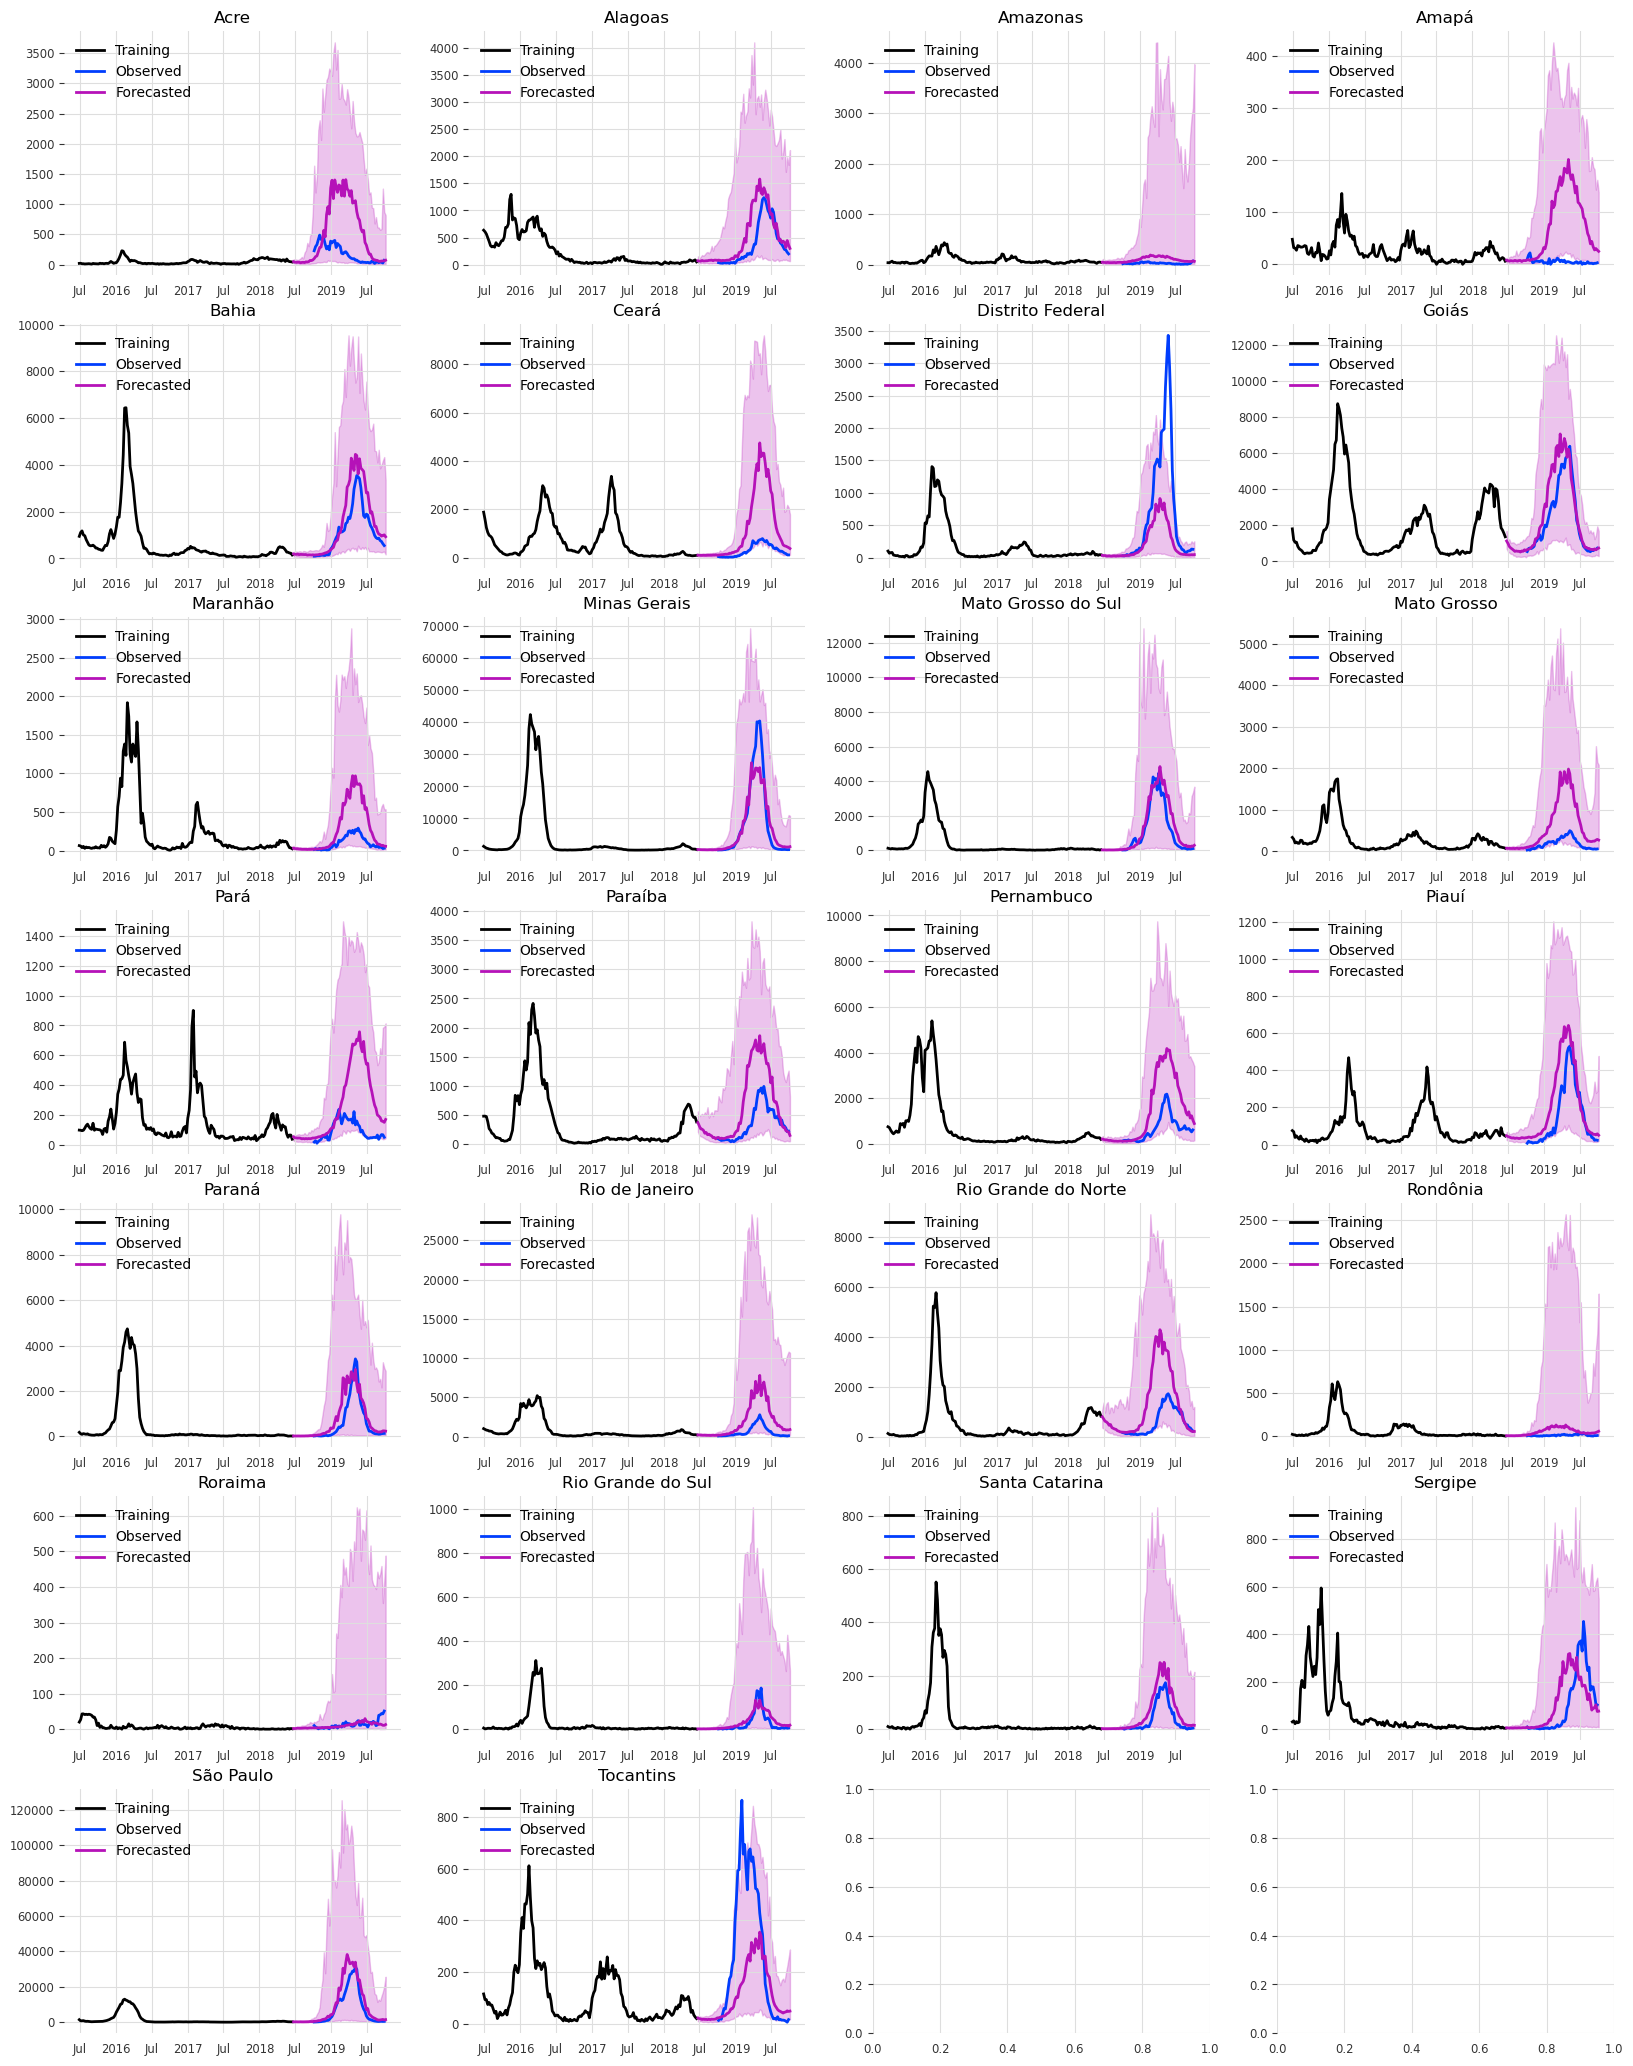

In [23]:
hp.generate_preds_obs_den_plot(train1a, val1a, val_predict, uf_list, uf_list, label_list = uf_name_list, train_limit = 156, height = 26)

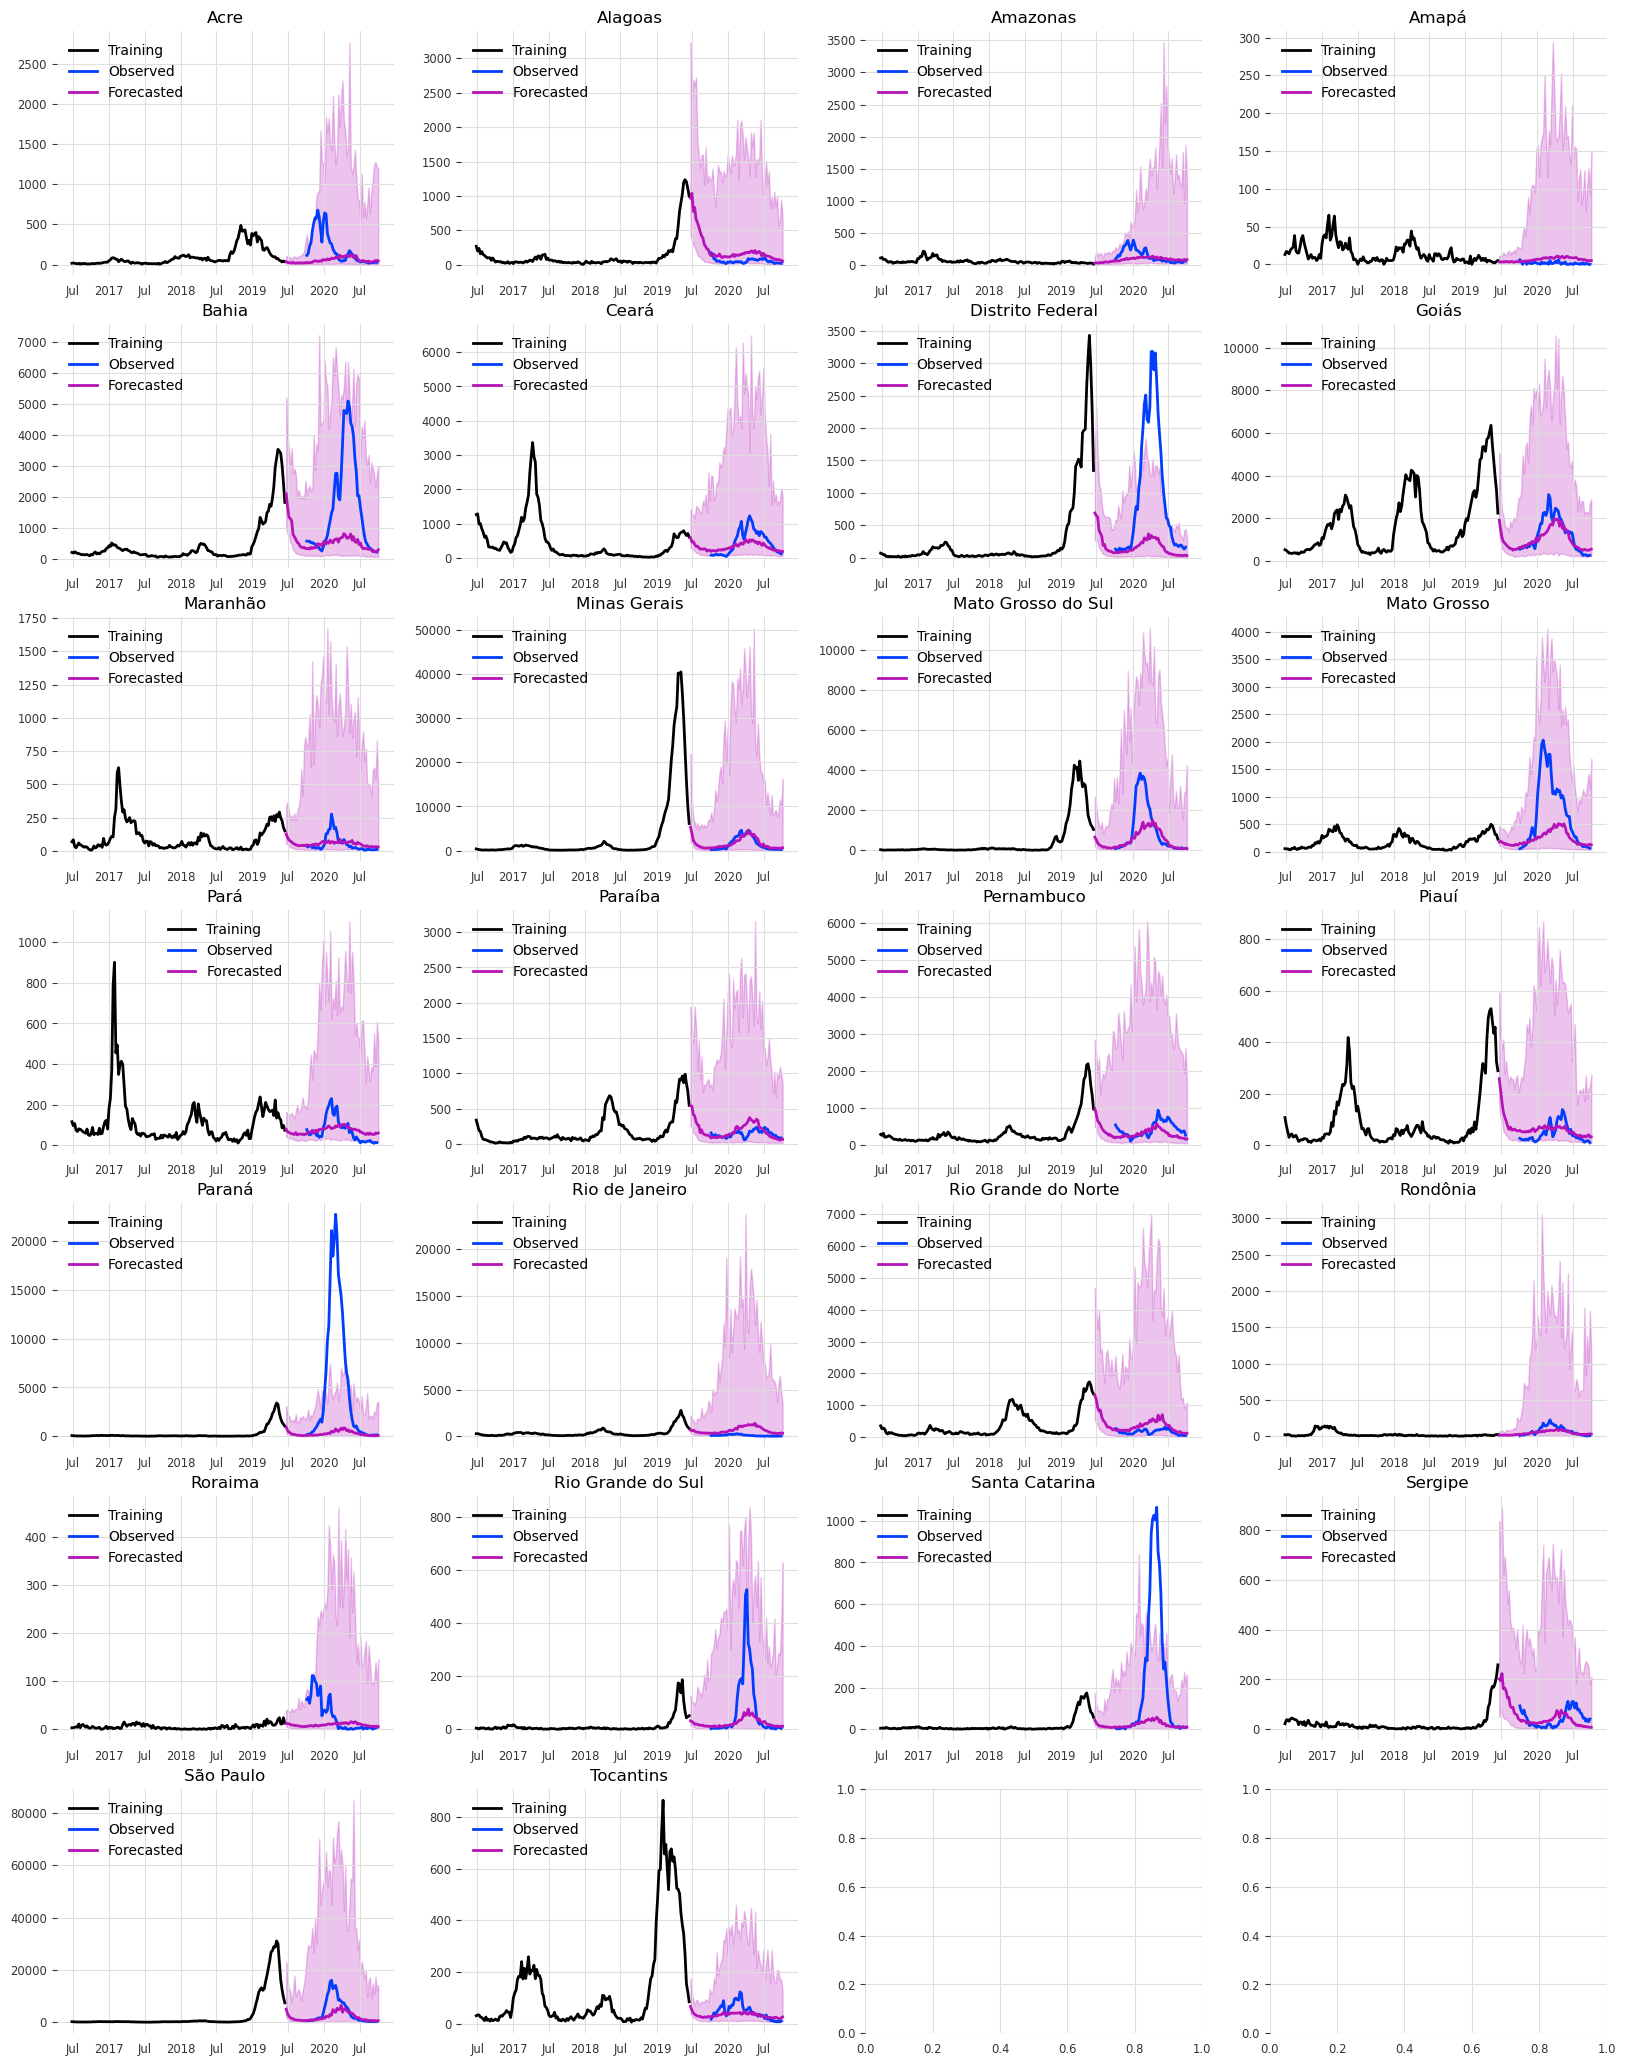

In [24]:
hp.generate_preds_obs_den_plot(train1b, val1b, val1b_predict, uf_list, uf_list, label_list = uf_name_list, train_limit = 156, height = 26)

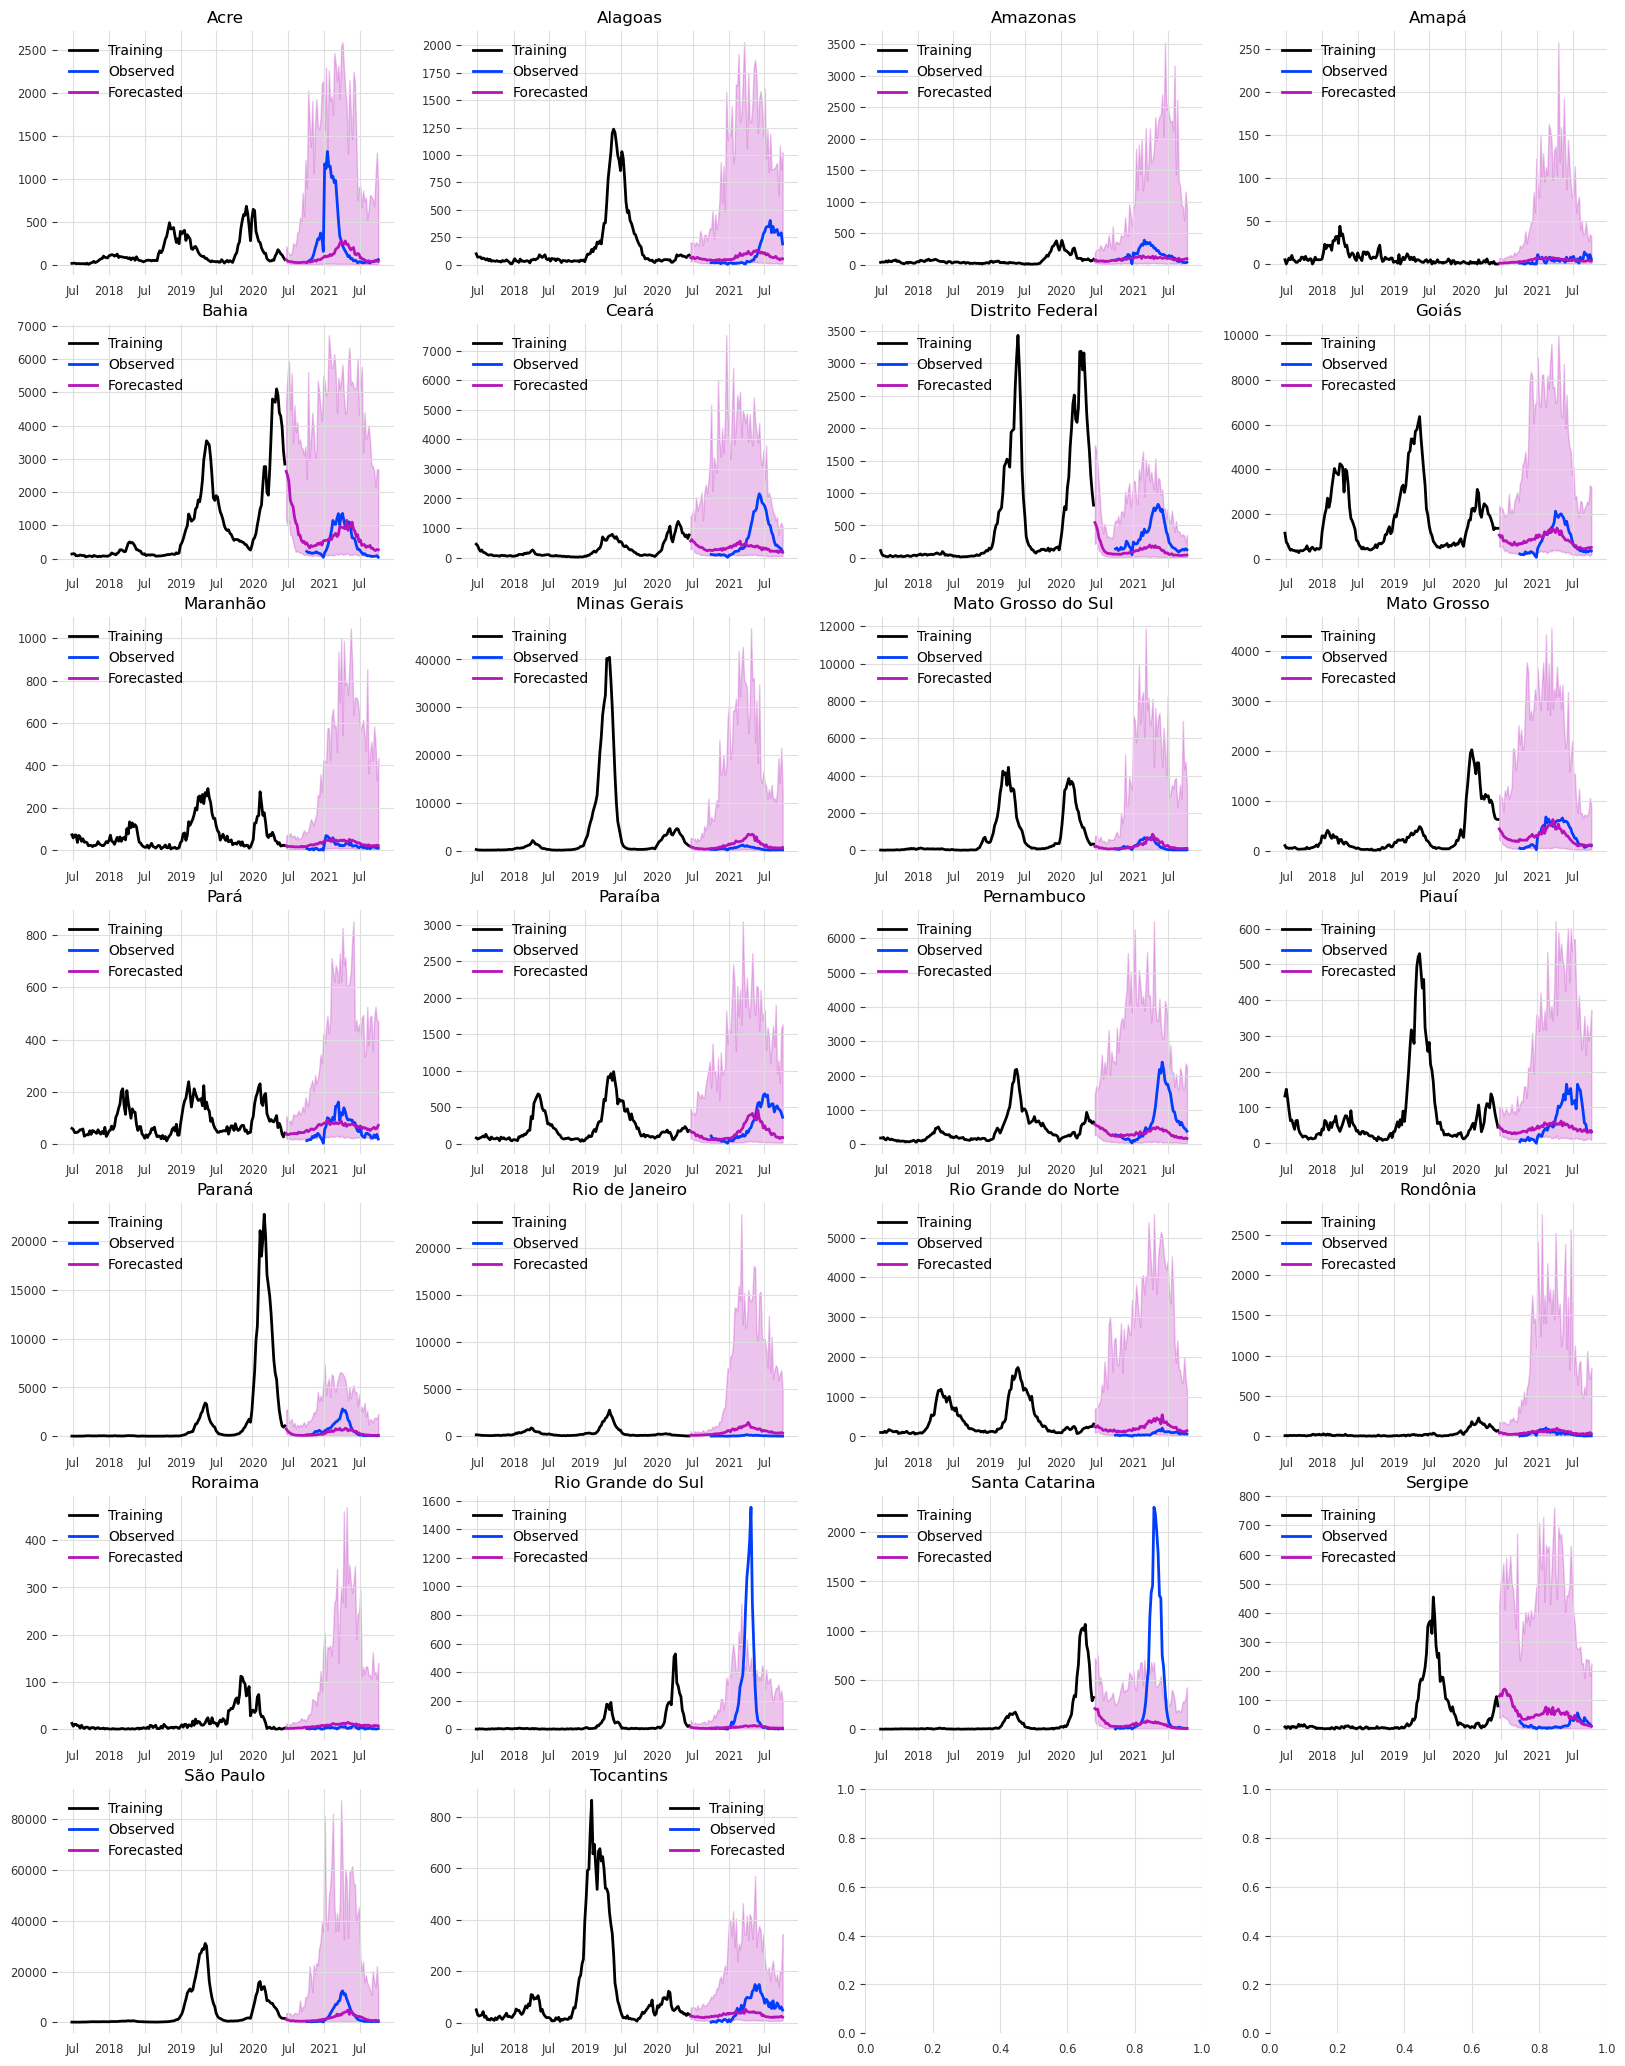

In [25]:
hp.generate_preds_obs_den_plot(train1c, val1c, val1c_predict, uf_list, uf_list, label_list = uf_name_list, train_limit = 156, height = 26)

In [26]:
hp.norm_metric_list(val1a, val1a_predict, train1a, series_summ_func = np.mean, metric = mql, quantiles = quantiles)

0.06971427051554561

In [27]:
hp.norm_metric_list(val1b, val1b_predict, train1b, series_summ_func = np.mean, metric = mql, quantiles = quantiles)

0.07770660108454934

In [28]:
hp.norm_metric_list(val1c, val1c_predict, train1c, series_summ_func = np.mean, metric = mql, quantiles = quantiles)

0.04620869960825886

In [29]:
def norm_metric(curr_obs, curr_preds, curr_normer, summ_func = None, metric = mae, quantiles = None):
    """
    Computes a normalised version of some Darts metric given an observed, predicted, and normalising TimeSeries.
    Note that this function assumes that all inputs are on their natural scales (should invert any log transforms or min-max scaling)

    Parameters:
    curr_obs (TimeSeries): Darts TimeSeries of observed values to compute metrics against
    curr_preds (TimeSeries): Darts TimeSeries forecasted values to commpute metrics with
    curr_normer (TimeSeries): Darts TimeSeries that serves as the basis of min-max values to normalise metrics (usually the training set)
    summ_func (function): Function to summarise the normalised per component metrics
    metric (function): Darts metric function (see: https://unit8co.github.io/darts/generated_api/darts.metrics.metrics.html)

    Returns:
    Value of the computed metric summarised (if summ_func is not None) or an array containing the metric per component (if summ_func is None)
    """
    curr_preds = curr_preds.slice_intersect(curr_obs) #Get the part of the forecast that intersects with the observation
    assert len(curr_preds) == len(curr_obs) #Check that the forecasts and observations match in length
    
    bounds_list = [] 
    for comp in curr_normer.components: #Use the normer series to find the min and max per component
        values = curr_normer[comp].values()
        comp_min = values.min()
        comp_max = values.max()
        bounds_list.append((comp_min, comp_max))

    if metric is mql and (quantiles is not None):
        met_per_comp = metric(curr_obs, curr_preds, component_reduction = None, q = quantiles)
        met_per_comp = [np.mean(curr_errs) for curr_errs in met_per_comp]
    else:
        met_per_comp = metric(curr_obs, curr_preds, component_reduction = None) #Get the metric value per component
    if len(curr_normer.components) == 1:
        met_per_comp = [met_per_comp]
    norm_met_vals = []
    for met, min_max in zip(met_per_comp, bounds_list):
        curr_min = min_max[0]
        curr_max = min_max[1]
        norm_met_vals.append(met / (curr_max - curr_min)) #Normalise the component error based on the min and max for each component
    norm_met_vals = np.array(norm_met_vals)

    #Whether to summarise the metric values or to just return the whole array
    if summ_func is None:
        return norm_met_vals
    else:
        return summ_func(norm_met_vals)

def norm_metric_list(obs_list, preds_list, normer_list, comp_summ_func = None, series_summ_func = None, metric = mae, quantiles = None):
    """
    Computes a normalised metric using a list of observed, predicted, and normalising series. Function assumes that all series are on
    their natural scales. 

    Parameters:
    obs_list (list): List of Darts TimeSeries containing observed values to compute metrics against
    preds_list (list): List of Darts TimeSeries containing forecasted values to commpute metrics with
    normer_list (list): List of Darts TimeSeries that serve as the basis of min-max values to normalise metrics (usually the training set)
    comp_summ_func (function): Function to summarise the normalised per component metrics
    series_summ_func (function): Function to summarise metrics across different series
    metric (function): Darts metric function (see: https://unit8co.github.io/darts/generated_api/darts.metrics.metrics.html)
    """
    result = []
    for curr_obs, curr_preds, curr_normer in zip(obs_list, preds_list, normer_list):
        met_val = norm_metric(curr_obs, curr_preds, curr_normer, summ_func = comp_summ_func, metric = metric, quantiles = quantiles)
        result.append(met_val)
    result = np.array(result)

    if series_summ_func is None:
        return result
    else:
        return series_summ_func(result)